# SDO/HMI maps of spots and faculae: tutorial

`sunsim.sdo` turns SDO/HMI images of the Sun into the **spot and facula maps** that SunSim simulates (`active_region_mask`, section 8 of the main tutorial): for every day, a continuum image and a magnetogram give a map of the spots and a map of the faculae, from which SunSim computes the light curve, the spectra or the CCFs (RV, FWHM, BIS) of the Sun as a star.

| section | content |
|---|---|
| 1 | The method: how every pixel is classified |
| 2 | Setup: the HMI images (and how to download them) |
| 3 | One day: read, identify, plot (3.1); the thresholds (3.2) |
| 4 | A time series of maps (`make_sdo_maps`) |
| 5 | From the maps to the light curve and the RV with SunSim |
| 6 | Large runs (years of days, full resolution): cell filling factors, workers, chunks |
| 7 | Comparison with the observations (TSI, HARPS-N): MAD, RMS, plots (`sunsim.observations`) |
| 8 | The same in a terminal (`sunsim-sdo-maps`) |
| 9 | API |

It needs `sunpy` (and `drms` to download): `pip install sunpy drms`, or `pip install "sunsim[sdo]"`.

## 1. The method

Two HMI images of the same epoch: the **continuum intensity without limb darkening** (`hmi.Ic_noLimbDark_720s`) and the **line-of-sight magnetogram** (`hmi.M_45s`). Every pixel of the disc is classified as in Yeo et al. (2013) and Sen et al. (2023):

| step | rule | parameter (default) |
|---|---|---|
| 1. noise | \|B\| below the noise threshold is set to 0; the threshold is given for the 4096 × 4096 images and scaled by N/4096 for images resampled to N × N pixels (the noise of the mean of k × k pixels is 1/k) | `noise_th` = 8 G |
| 2. foreshortening | B / μ, with μ = cos(heliocentric angle) | |
| 3. active pixels | \|B\| / μ > B_th / μ | `B_th` = 24 G |
| 4. spots | active pixels darker than I_th × ⟨I_quiet⟩, the mean intensity of the quiet Sun (pixels of the disc that are not active); the other active pixels are bright features | `I_th` = 0.89 |
| 5. plage / network | connected groups of bright pixels larger than A_th micro-hemispheres (projected at μ = `mu_area`) are plage, the smaller ones network | `A_th` = 20 µHem, `mu_area` = 0.1 |

The **spot map** contains the spots, the **facula map** the plage (`faculae='plage+network'`: the network too). Both are cut to the square of the disc and turned back by 180° (HMI stores the images upside down, `CROTA2` = 180°): row 0 is the south of the disc and the rotation moves the regions from left to right. Read them with `active_region_mask(folder, origin='lower')`.

Compared with the previous script (`identification_utils.py`, `simu_rv_opt_fast.py`): μ is now cos θ (it was ρ/R, the sine), the noise threshold is scaled by N/4096 (it was multiplied by `int(N/4096)`, i.e. 0 below 4096 pixels: no noise threshold), the spot threshold refers to the quiet Sun (it was the mean of the active pixels), and a day with a missing image is skipped (the previous day was processed again).

## 2. Setup

The HMI images are read from the folder of the path `sdo_data` (`local_paths.ini`, see section 2.2 of the main tutorial), with the names of the JSOC exports: `hmi.ic_nolimbdark_720s.YYYYMMDD_*continuum.fits` and `hmi.m_45s.YYYYMMDD_*magnetogram.fits` (the first file of the day of each series). The maps are written in a temporary folder.

In [1]:
import os, tempfile
import numpy as np
import matplotlib.pyplot as plt
from sunsim import sdo, local_path, active_region_mask, max_rings, StarSim, flux_grid, CCF_grid, mask_weights, black_body
from sunsim import plot_utils

DATA = local_path('sdo_data')                                        # folder of the HMI images
OUT = os.path.join(tempfile.gettempdir(), 'sunsim_sdo_tutorial')     # the maps
print('HMI images:', DATA)
print('maps:', OUT)

HMI images: /Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/My Drive/storage/sdo_fits
maps: /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/sunsim_sdo_tutorial


**Downloading the images.** `sdo.download_hmi(start, end, folder, email)` downloads from JSOC the continuum and the magnetogram of every day (the first images after 00:00 TAI), with `sunpy.net.Fido`. It needs an email address registered at JSOC (http://jsoc.stanford.edu/ajax/register_email.html); the days already in the folder are not downloaded again. `make_sdo_maps(..., download=True, email=...)` does it before making the maps.

In [2]:
DOWNLOAD = False                       # True: download the days of this tutorial (needs a JSOC email)
if DOWNLOAD:
    sdo.download_hmi('2017-07-01', '2017-07-11', DATA, email='you@institute.org')

## 3. One day

### 3.1 Read, identify, plot

`read_hmi_day(folder, date)` reads the two images of a day as `sunpy` maps; `identify_day(cont_map, los_map, size=512)` resamples them to 512 × 512 pixels, classifies every pixel (section 1) and returns the maps for SunSim (`spot_map`, `facula_map`), the masks of the spots, plage and network, the filling factors (% of the disc, projected) and the numbers of spots and plages.

/Users/sophiestucki/miniforge3/envs/env_sunsim/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


maps for SunSim: (468, 468) (the square of the disc)
ff_sp = 0.099 %, ff_fc = 3.237 %, ff_nt = 0.000 %, 1 spots, 4022 plages
noise threshold 1.00 G (512 px), plage: groups > 0.69 pixels, <I_quiet> = 0.9998


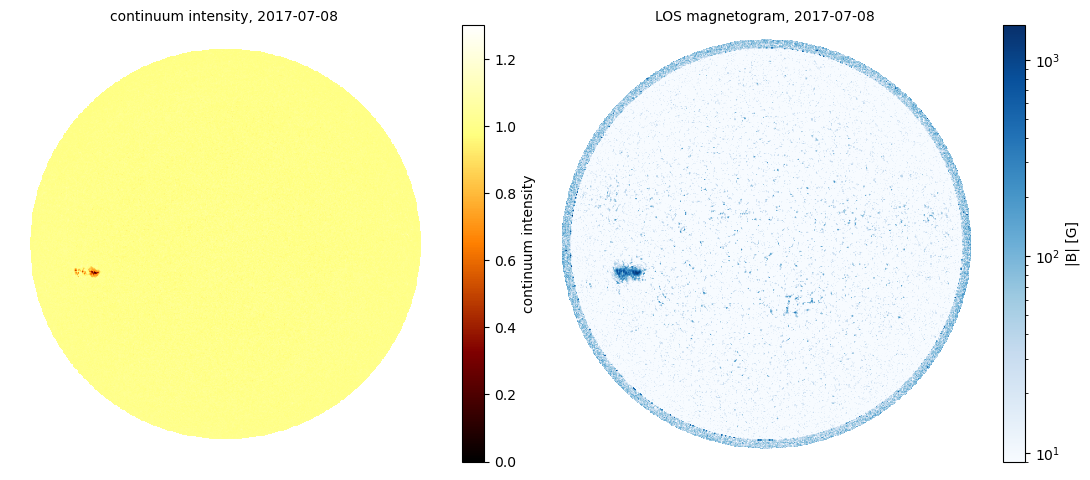

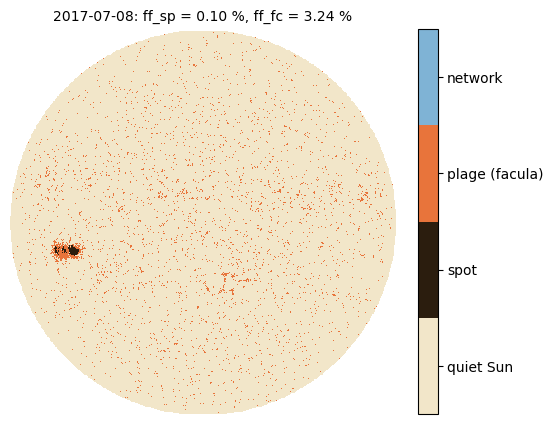

In [3]:
cont_map, los_map = sdo.read_hmi_day(DATA, '2017-07-08')
day = sdo.identify_day(cont_map, los_map, size=512)

print('maps for SunSim:', day['spot_map'].shape, '(the square of the disc)')
print('ff_sp = %.3f %%, ff_fc = %.3f %%, ff_nt = %.3f %%, %d spots, %d plages' %
      (day['ff_sp'], day['ff_fc'], day['ff_nt'], day['n_spots'], day['n_plages']))
print('noise threshold %.2f G (512 px), plage: groups > %.2f pixels, <I_quiet> = %.4f' %
      (day['noise_th'], day['area_th_pixels'], day['I_quiet']))

sdo.plot_hmi(day['cont_map'], day['los_map'])
plt.show()
sdo.plot_identification(day)
plt.show()

### 3.2 The thresholds

`I_th` sets which active pixels are spots (lower: only the darkest umbrae; higher: more penumbra), and `A_th` with `mu_area` separates plage from network. With the default `mu_area = 0.1` the threshold is projected to the limb, where an area looks 10 times smaller: at 512 pixels, 20 µHem is then less than one pixel and every bright group is plage (`ff_nt` = 0). `mu_area = 1` (the area at the disc centre, ~7 pixels) leaves the small groups as network. Below: the two choices for the same day.

I_th = 0.85: ff_sp = 0.086 %, 1 spots
I_th = 0.89: ff_sp = 0.099 %, 1 spots


I_th = 0.93: ff_sp = 0.112 %, 1 spots


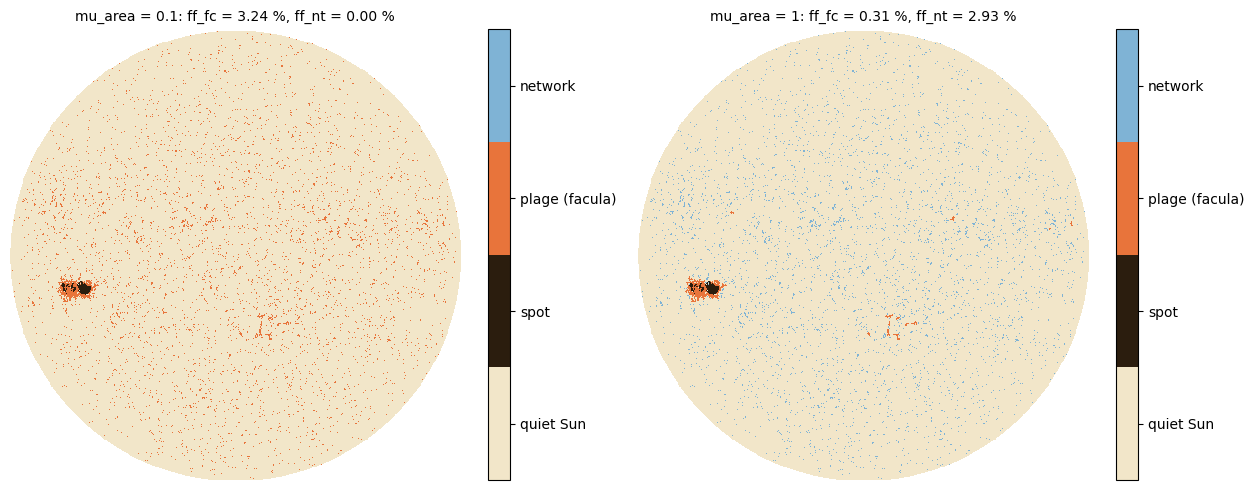

In [4]:
for I_th in (0.85, 0.89, 0.93):
    d = sdo.identify_day(cont_map, los_map, size=512, I_th=I_th)
    print('I_th = %.2f: ff_sp = %.3f %%, %d spots' % (I_th, d['ff_sp'], d['n_spots']))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, mu_area in zip(axes, (0.1, 1.0)):
    d = sdo.identify_day(cont_map, los_map, size=512, mu_area=mu_area)
    sdo.plot_identification(d, ax=ax, title='mu_area = %g: ff_fc = %.2f %%, ff_nt = %.2f %%' % (mu_area, d['ff_fc'], d['ff_nt']))
plt.tight_layout()
plt.show()

## 4. A time series of maps

`make_sdo_maps(data_folder, out_folder, start, end, step=1, size=512)` does section 3 for every `step`-th day from `start` to `end` (excluded) and writes the maps in `out_folder`: `spot_map_{t}.npy` and `faculae_map_{t}.npy` (`uint8` masks; `fmt='txt'` for text files as the old StarSim reads them), with `t` the days since `start` (`epoch='index'`: 0, 1, 2, ... as the previous script). It also writes `summary.csv` (filling factors and numbers of features of every epoch) and `parameters.txt`, and returns the same numbers. The days without both images are skipped.

epochs: [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.] | skipped: none


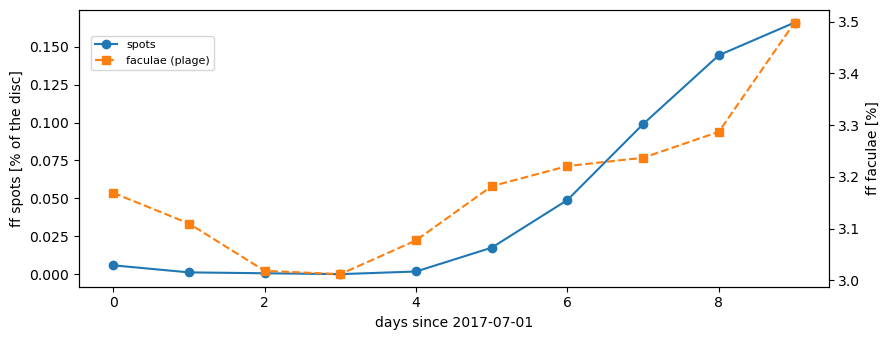

In [5]:
res = sdo.make_sdo_maps(DATA, OUT, '2017-07-01', '2017-07-11', size=512, verbose=False)
print('epochs:', res['times'], '| skipped:', res['skipped'] or 'none')

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(res['times'], res['ff_sp'], 'o-', label='spots')
ax.set_ylabel('ff spots [% of the disc]')
ax2 = ax.twinx()
ax2.plot(res['times'], res['ff_fc'], 's--', color='C1', label='faculae (plage)')
ax2.set_ylabel('ff faculae [%]')
ax.set_xlabel('days since 2017-07-01')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.9), fontsize=8)
plt.tight_layout()
plt.show()

## 5. From the maps to the light curve and the RV with SunSim

The folder of the maps is given to `active_region_mask(folder, origin='lower')` and to `StarSim(..., active_regions_mask=maps)`, as any 2D maps (main tutorial, section 8). `max_rings` gives the largest number of rings the resolution of the maps supports. The spectra are the MURaM spectra of the main tutorial (paths `muram_spectra`, `muram_lowres_spectra`): photometry from the low resolution ones, CCFs from the high resolution ones in 5000-5600 Å (the spot: quiet × black-body ratio at 5770 − 500 K).

/Users/sophiestucki/sunsim/sunsim/active_region_mask.py:120: UserWarning: 20 maps of the same epoch with two file names in /var/folders/zk/_1ntmgv17vb6c_z2qnyqyytc0000gn/T/sunsim_sdo_tutorial (e.g. spot_map_2.npy and spot_map_2.0.npy): the newest file is used
  warnings.warn("%d maps of the same epoch with two file names in %s (e.g. %s and %s): the newest file is used"


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


epochs: [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.] | rings: 20


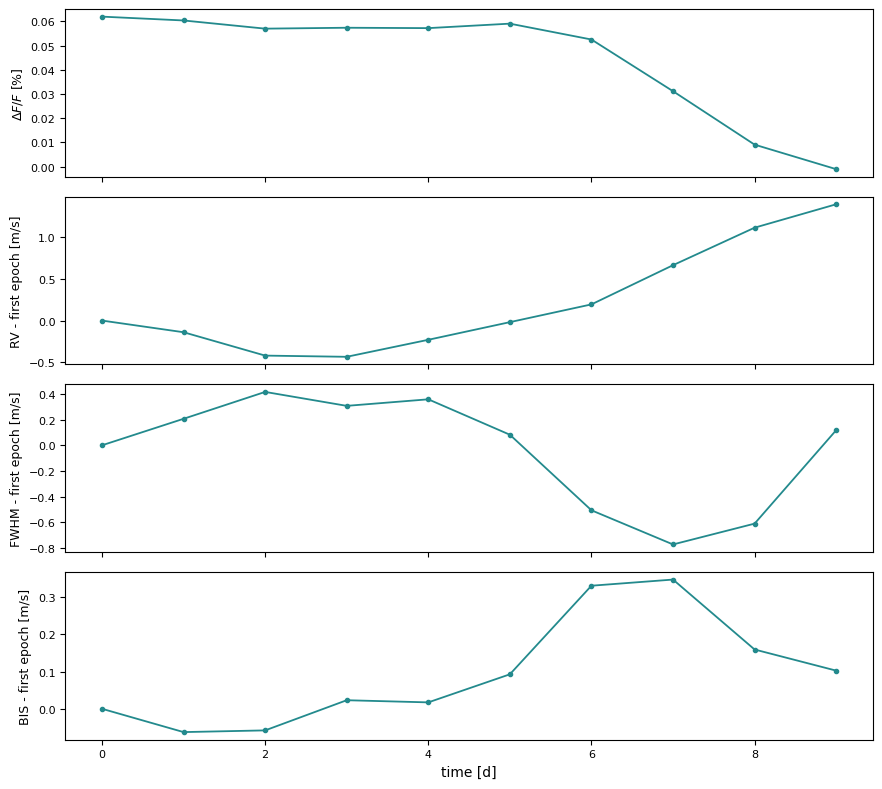

In [6]:
maps = active_region_mask(OUT, origin='lower')
N = min(20, max_rings(day['spot_map'].shape))
print('epochs:', maps.times, '| rings:', N)

T, dT = 5770.0, 500.0
def muram(folder, name):
    return {float(k): v for k, v in np.load(local_path(folder) / name, allow_pickle=True).item().items()}
def spot_of(quiet):
    return {m: {'wav': d['wav'], 'intensity': d['intensity'] * black_body(d['wav'], T - dT) / black_body(d['wav'], T)}
            for m, d in quiet.items()}

# photometry: low resolution spectra
low_q = muram('muram_lowres_spectra', 'av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy')
low_f = muram('muram_lowres_spectra', 'av_solar_faculae_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy')
phot = {}
for key, spectra in (('qp', low_q), ('sp', spot_of(low_q)), ('fc', low_f)):
    g = flux_grid(N, spectra, key, None, 3800, 8000, mode='photometry')
    g.built_grid()
    phot[key] = g

# CCFs: high resolution spectra in 5000-5600 A, HARPS mask (computed in air)
def cut(spectra, lo=5000.0, hi=5600.0):
    return {m: {'wav': d['wav'][(d['wav'] > lo) & (d['wav'] < hi)], 'intensity': d['intensity'][(d['wav'] > lo) & (d['wav'] < hi)]}
            for m, d in spectra.items()}
high_q = cut(muram('muram_spectra', 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy'))
high_f = cut(muram('muram_spectra', 'av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy'))
wvm, fm = mask_weights(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas')
keep = (wvm > 5010) & (wvm < 5590)
rv = np.arange(-18000, 18250, 250.0)
ccf = {}
for key, spectra in (('qp', high_q), ('sp', spot_of(high_q)), ('fc', high_f)):
    g = CCF_grid(N, spectra, rv, wvm[keep], fm[keep], normalization='none')
    g.built_grid(bisector=None)
    ccf[key] = g

sun = StarSim(maps.times, N, inclination=np.deg2rad(7.25), rotation_period=25.4, active_regions_mask=maps,
              mode=['photometry', 'ccf'], flux_grid_qp=phot['qp'].grid, flux_grid_sp=phot['sp'].grid,
              flux_grid_fc=phot['fc'].grid, ccf_grid_qp=ccf['qp'], ccf_grid_sp=ccf['sp'], ccf_grid_fc=ccf['fc'])
sun.generate_timeseries(verbose=False)
fig, axes = plot_utils.plot_activity({'SDO/HMI, July 2017': sun}, quiet_flux=phot['qp'].total_brightness,
                                     reference='first', marker='o-', figsize=(9, 8))
plt.show()

## 6. Large runs

For thousands of days at full resolution (4096 × 4096 pixels) the maps are not needed by SunSim, only the filling factors of its cells. `make_sdo_maps(..., n_rings=N)` projects every day on the cells of a SunSim grid of `N` rings right after the identification (`cells_N<N>/ff_<t>.npy`, float32, ~50 kB per day for N = 70) and collects them in `filling_factors_N<N>.npz`; `load_filling_factors(out_folder, N)` gives them to `StarSim(..., active_regions_mask=...)` in place of the maps (nothing is read or projected again).

| option | what it does |
|---|---|
| `n_rings=N` | cell filling factors of a grid of N rings (the rings of the simulation; `max_rings(size)` for the resolution) |
| `fmt='npz'` | maps saved as compressed bit masks (~3 kB per day at 4096 px instead of 2 × 16 MB); `fmt=None`: no map at all |
| `workers=k` | k days in parallel (processes; ~1.2 GB per worker at 4096 px). In a Python *script*, call it under `if __name__ == '__main__':` |
| `resume=True` | the days already done (`days/<date>.json`) are skipped: a run that stopped can be started again |

Measured at 4096 px: 1.7 s and 1.4 GB per day with one worker, ~1.1 s per day with 3 workers: 3000 days take ~1 h with one worker, ~20-30 min with 4.

The simulation itself: `simulate_in_chunks(time, chunk_size, **StarSim arguments)` runs StarSim on chunks of epochs and joins the outputs (the memory is that of one chunk), (with maps, the CCFs of all the cells are kept: 3 x n_cells x n_rv values, ~43 MB at 70 rings). The CCF time series is a result like the RV: `StarSim.results()` / `save_results(path)` (and `ccf.txt` with the terminal command). Below: the same 10 days as in section 4, with the cell filling factors and two workers, simulated in chunks of 4 days.

**Many thresholds at once.** `make_sdo_sweep(data, out, start, end, size=4096, I_th=[0.85, 0.89, 0.95], A_th=[20, 100], n_rings=N, workers=4)` makes every combination of the thresholds (any of `noise_th`, `B_th`, `I_th`, `A_th`, `mu_area`, `faculae` can be a list), each in its folder `out/<set>` (e.g. `noise8_B24_I0.89_A20_mu0.1`, listed in `out/sets.csv`). Every day is read, resampled and its μ computed **once** for all the sets, then classified for each. `simulate_sdo_sets(conf, folders, grids_cache='grids.pkl')` simulates all the folders with the configuration of an old StarSim run: the grids (spectra, CCFs of the rings) are computed once, kept in `grids.pkl` and read again by the next calls with the same configuration; a folder already simulated (same configuration, same maps) is not simulated again. A sweep can be extended later with new values in the same `out`: only the new sets are classified and simulated. In a terminal: give several values to the options (section 8).

In [7]:
OUT_CELLS = os.path.join(tempfile.gettempdir(), 'sunsim_sdo_tutorial_cells')
res = sdo.make_sdo_maps(DATA, OUT_CELLS, '2017-07-01', '2017-07-11', size=512, fmt='npz', n_rings=N, workers=2,
                        verbose=False)
cells = sdo.load_filling_factors(OUT_CELLS, N)
print('epochs:', cells.times, '| files:', sorted(os.listdir(OUT_CELLS)))

from sunsim import simulate_in_chunks
out = simulate_in_chunks(cells.times, chunk_size=4, N_rings=N, inclination=np.deg2rad(7.25), rotation_period=25.4,
                         active_regions_mask=cells, mode=['photometry', 'ccf'], flux_grid_qp=phot['qp'].grid,
                         flux_grid_sp=phot['sp'].grid, flux_grid_fc=phot['fc'].grid, ccf_grid_qp=ccf['qp'],
                         ccf_grid_sp=ccf['sp'], ccf_grid_fc=ccf['fc'])
print('max |difference| with section 5: flux %.1e (relative), RV %.1e m/s'
      % (np.max(np.abs(out['flux_var'] / sun.flux_var - 1)), np.max(np.abs(out['rv_var'] - sun.rv_var))))

epochs: [0. 1. 2. 3. 4. 5. 6. 7. 8. 9.] | files: ['cells_N20', 'days', 'faculae_map_0.0.npz', 'faculae_map_1.0.npz', 'faculae_map_2.0.npz', 'faculae_map_3.0.npz', 'faculae_map_4.0.npz', 'faculae_map_5.0.npz', 'faculae_map_6.0.npz', 'faculae_map_7.0.npz', 'faculae_map_8.0.npz', 'faculae_map_9.0.npz', 'filling_factors_N20.npz', 'parameters.txt', 'spot_map_0.0.npz', 'spot_map_1.0.npz', 'spot_map_2.0.npz', 'spot_map_3.0.npz', 'spot_map_4.0.npz', 'spot_map_5.0.npz', 'spot_map_6.0.npz', 'spot_map_7.0.npz', 'spot_map_8.0.npz', 'spot_map_9.0.npz', 'summary.csv']
max |difference| with section 5: flux 4.4e-12 (relative), RV 4.6e-08 m/s


## 7. Comparison with the observations

`sunsim.observations` compares a simulation with the observed Sun:

* photometry: total solar irradiance of SORCE/TIM (`load_sorce`, IDL `.sav`) and TSIS-1 (`load_tsis`, csv); `compare_photometry` matches the days, divides both by their mean over the matched days and gives the residuals [ppm];
* RV (or FWHM, BIS, contrast): HARPS-N solar telescope (`load_harpsn`, averaged per day, km/s converted to m/s); `compare_rv` removes the medians, cuts the series at the HARPS-N interventions (`load_interventions`), keeps in every instrumental period the shift of the days (−1, 0, +1) with the smallest RMS and removes one offset per period;
* statistics: `mad(x)` = median(|x − median(x)|) and `rms(x)` (= std) of the residuals and of the observations; `print_summary`;
* figures: `plot_comparison` (TSI + residuals, RV + residuals), `plot_photometry_comparison`, `plot_rv_comparison`, `plot_correlation`.

The simulation times are days since `start` (the `start` of `make_sdo_maps`). The files are found with `local_path`: `harpsn_sun`, `harpsn_interventions`, `sorce_tsi`, `tsis_tsi`. Here: the three months 2015-09-01 to 2015-12-01, with the cell filling factors of section 6 (512 px, the grids of section 5), against SORCE/TIM and HARPS-N (TSIS-1 starts in 2018).

87 days simulated; skipped: 2015-09-28, 2015-10-06, 2015-10-28, 2015-10-29


SORCE/TIM    87 days  residuals: MAD    61.2 ppm  RMS    83.1 ppm   (observed: MAD   146.9  RMS   238.7 ppm)
  period  0:     0.5 ->    42.0  sim   39  obs   31  matched   28  shift    1  RMS 1.017 m/s
  period  1:    42.0 ->    89.5  sim   46  obs   27  matched   25  shift    0  RMS 1.139 m/s
RV           53 days  residuals: MAD 0.811 m/s  RMS 1.091 m/s   (observed: MAD 0.902  RMS 1.530 m/s; RMS reduced by 28.7 %)
  period  0:     0.5 ->    42.0  sim   39  obs   31  matched   28  shift    1  RMS 1.910 m/s
  period  1:    42.0 ->    89.5  sim   46  obs   27  matched   24  shift    1  RMS 1.843 m/s
FWHM         52 days  residuals: MAD 1.259 m/s  RMS 1.903 m/s   (observed: MAD 1.685  RMS 2.182 m/s; RMS reduced by 12.8 %)
  period  0:     0.5 ->    42.0  sim   39  obs   31  matched   28  shift    1  RMS 0.885 m/s
  period  1:    42.0 ->    89.5  sim   46  obs   27  matched   25  shift   -1  RMS 1.085 m/s
BIS          53 days  residuals: MAD 0.631 m/s  RMS 0.994 m/s   (observed: MAD 0.815 

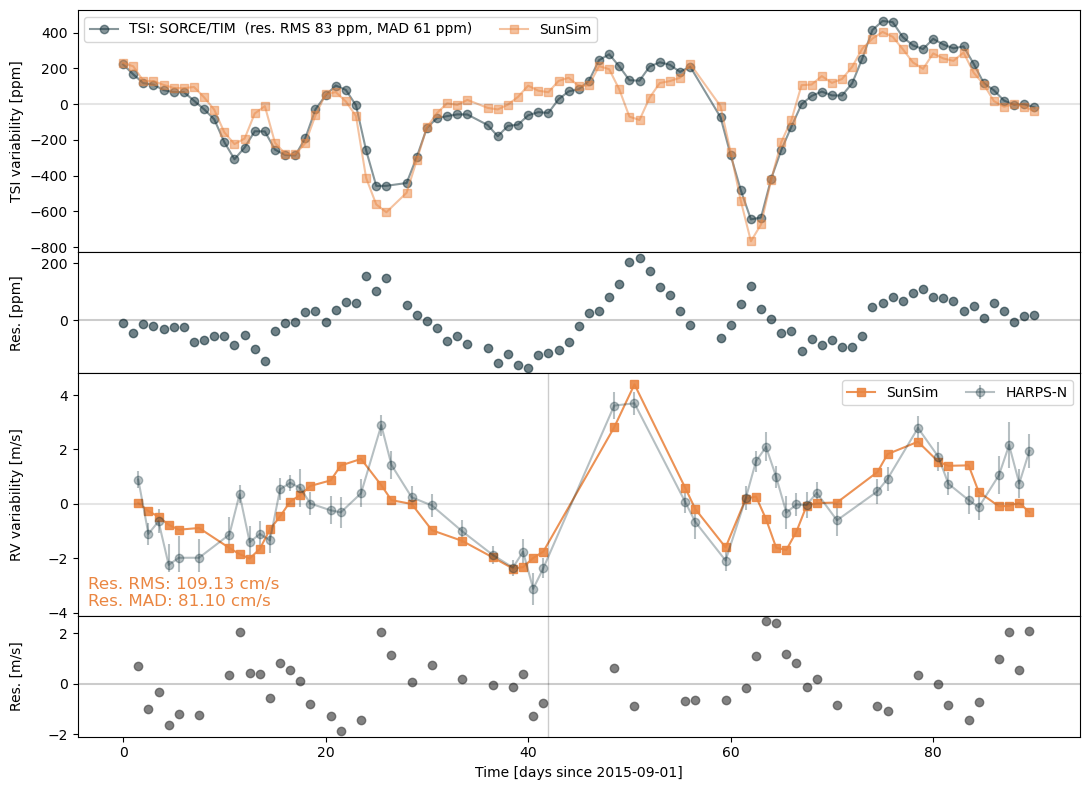

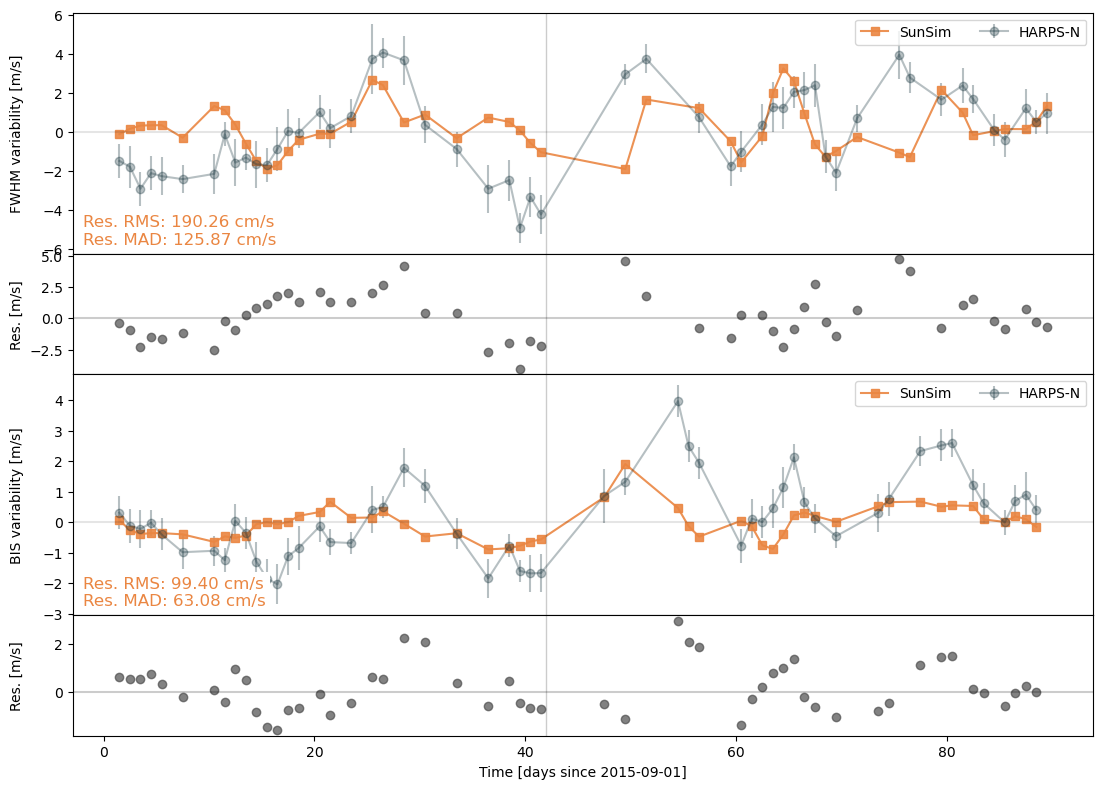

In [8]:
from sunsim import observations as obs

START, END = '2015-09-01', '2015-12-01'           # t = 0 on START; END excluded
OUT_2015 = os.path.join(tempfile.gettempdir(), 'sunsim_sdo_tutorial_2015')
res15 = sdo.make_sdo_maps(DATA, OUT_2015, START, END, size=512, fmt=None, n_rings=N, workers=3, verbose=False)
cells15 = sdo.load_filling_factors(OUT_2015, N)
print('%d days simulated; skipped: %s' % (len(cells15.times), ', '.join(res15['skipped']) or 'none'))

sun15 = StarSim(cells15.times, N, inclination=np.deg2rad(7.25), rotation_period=25.4, active_regions_mask=cells15,
                mode=['photometry', 'ccf'], flux_grid_qp=phot['qp'].grid, flux_grid_sp=phot['sp'].grid,
                flux_grid_fc=phot['fc'].grid, ccf_grid_qp=ccf['qp'], ccf_grid_sp=ccf['sp'], ccf_grid_fc=ccf['fc'])
sun15.generate_timeseries(verbose=False)

paths = {k: local_path(k, required=False) for k in ('harpsn_sun', 'harpsn_interventions', 'sorce_tsi', 'tsis_tsi')}
if None in paths.values():
    print('set the paths', [k for k, v in paths.items() if v is None], 'in local_paths.ini to run this comparison')
else:
    last = '2015-11-30'                                  # the last day (included) of the observations
    harps = obs.load_harpsn(paths['harpsn_sun'], START, end=last)
    sorce = obs.load_sorce(paths['sorce_tsi'], START, end=last)
    cuts = obs.load_interventions(paths['harpsn_interventions'], START)

    phot_cmp = obs.compare_photometry(sorce, sun15.obs_times, sun15.flux_var)
    rv_cmp = obs.compare_rv(harps, sun15.obs_times, sun15.rv_var, interventions=cuts)
    fwhm_cmp = obs.compare_rv(harps, sun15.obs_times, sun15.fwhm_var, quantity='fwhm', interventions=cuts)
    bis_cmp = obs.compare_rv(harps, sun15.obs_times, sun15.bis_var, quantity='bis', interventions=cuts)
    obs.print_summary(phot_cmp, [rv_cmp, fwhm_cmp, bis_cmp])

    # intensity (TSI) and RV
    fig, axes = obs.plot_comparison(phot_cmp, rv_cmp, start=START, figsize=(11, 8))
    plt.show()
    # activity indicators: FWHM and BIS
    fig, axes = obs.plot_comparison(None, [fwhm_cmp, bis_cmp], start=START, figsize=(11, 8))
    plt.show()


For a long run (e.g. 2015-07-18 to 2024-01-29 at 4096 px, ~3100 days), the same calls with the whole series: the residual RV RMS of the simulation of Stucki et al. is 0.80 m/s (MAD 0.49 m/s) against 2.41 m/s for the HARPS-N data alone (−67 %), over 21 instrumental periods. A FWHM of the simulation is the width of its CCF, which has the resolution of the simulated spectra, not that of HARPS-N: compare its variations (medians removed), as `compare_rv` does.

## 8. In a terminal

The same pipeline is a command (installed with the package; `python -m sunsim.sdo` does the same):

```bash
sunsim-sdo-maps --data /path/to/hmi --out maps/ --start 2017-07-01 --end 2017-07-11 --size 512
sunsim-sdo-maps --data /path/to/hmi --out maps/ --start 2015-07-18 --end 2024-01-29 --download --email you@institute.org
sunsim-sdo-maps ... --conf old.conf      # then the light curve, RV, FWHM, BIS, contrast and CCFs (simulate_old_config)
# sweep: 3 x 2 sets of thresholds, every day read once, the grids computed once (and kept in sweep/grids_<id>.pkl)
sunsim-sdo-maps --data hmi/ --out sweep/ --start 2015-07-18 --end 2024-01-29 --size 4096 --workers 4 --I-th 0.85 0.89 0.95 --A-th 20 100 --conf sun.conf
# later, more values in the same folder: only the new sets are made and simulated
sunsim-sdo-maps --data hmi/ --out sweep/ --start 2015-07-18 --end 2024-01-29 --size 4096 --workers 4 --I-th 0.85 0.89 0.92 0.95 --A-th 20 100 --conf sun.conf
```

| option | default | meaning |
|---|---|---|
| `--data`, `--out` | | folder of the HMI images, folder of the maps |
| `--start`, `--end`, `--step` | step 1 | days `start` ≤ day < `end`, every `step` days |
| `--size` | 512 | pixels of the maps (4096: full resolution) |
| `--noise-th`, `--B-th`, `--I-th`, `--A-th`, `--mu-area` | 8, 24, 0.89, 20, 0.1 | thresholds (section 1); several values: one set per combination in `--out/<set>` |
| `--faculae` | plage | `plage` or `plage+network` in the facula maps (several values: sets) |
| `--epoch`, `--format` | days, npy | `{t}` of the files (`days` since start or `index`), `npy`, `npz` (compressed bit masks), `txt` or `none` (no map; default with several sets) |
| `--n-rings` | | also write the filling factors of the cells of a grid of N rings (section 6) |
| `--workers`, `--no-resume` | 1 | days in parallel; do again the days already done |
| `--download`, `--email` | | download the missing days from JSOC first |
| `--conf` | | an old StarSim configuration with `sdo_input = 1`: simulate the maps with `simulate_old_config` and write `lc.txt`, `rv.txt`, `fwhm.txt`, `bis.txt`, `contrast.txt`, `ccf.txt`, `ccf_rv.txt` in `--out` |
| `--observables` | lc rv fwhm bis contrast | with `--conf`: what is simulated |
| `--grids-cache`, `--no-grids-cache` | `--out/grids_<id>.pkl` | with `--conf`: file of the grids, reused by the next runs with the same configuration |
| `--chunk-size` | all | with `--conf`: epochs simulated together (memory) |
| `--simulate-only` | | with `--conf`: no maps, simulate the sets already in `--out` |
| `--quiet` | | no progress lines |

## 9. API

| function | what it does |
|---|---|
| `make_sdo_maps(data_folder, out_folder, start, end, step=1, size=512, ...)` | maps of every day, `summary.csv`, `parameters.txt`; returns the filling factors |
| `download_hmi(start, end, folder, email, step=1)` | downloads the images from JSOC |
| `read_hmi_day(folder, date)`, `find_hmi_files(folder, date)` | the two maps (sunpy) / files of a day |
| `identify_day(cont_map, los_map, size=512, noise_th=8, B_th=24, I_th=0.89, A_th=20, mu_area=0.1, faculae='plage')` | classification of one day: maps for SunSim, masks, filling factors |
| `plot_hmi(cont_map, los_map)`, `plot_identification(day)` | figures |
| `classify_pixels(intensity, blos, mu, noise_th, B_th, I_th)` | steps 1-4 on arrays (no sunpy) |
| `split_plage_network(bright, area_th_pixels)` | step 5 on arrays |
| `count_spots(spot, sigma=2, threshold=0.2)` | number, centres and areas of the spots |
| `mu_from_rho(rho, radius)`, `mu_of_map(smap)` | μ = cos(heliocentric angle) |
| `noise_threshold_for(size, noise_th=8)` | noise threshold for images of size × size pixels |
| `area_threshold_pixels(smap, A_th, mu)`, `deprojected_area_uhem(smap, mask)` | areas in pixels / micro-hemispheres |
| `make_sdo_sweep(data_folder, out_folder, start, end, I_th=[...], A_th=[...], ..., n_rings=N)` | all the combinations of the thresholds, every day read once; `{label: result}` |
| `parameter_sets(...)`, `set_label(params)` | the combinations, the name of the folder of a set |
| `simulate_sdo_sets(conf, folders, grids_cache=None, chunk_size=None)` | simulation of several folders, the grids computed once (and kept in `grids_cache`) |
| `load_filling_factors(out_folder, n_rings)` | cell filling factors of `make_sdo_maps(..., n_rings=...)` for `StarSim(active_regions_mask=...)` |
| `main(argv)` | the terminal command |

`sunsim.observations` (section 7):

| function | what it does |
|---|---|
| `load_harpsn(path, start, end=None, daily=True)`, `daily_average(obs, start)` | HARPS-N rv, fwhm, bis [m/s], contrast, per day (mean, std, number) |
| `load_sorce(path, start, end=None)`, `load_tsis(path, start, end=None)` | TSI of SORCE/TIM and TSIS-1 |
| `load_interventions(path, start)` | days of the HARPS-N interventions |
| `mad(x)`, `rms(x)` | median absolute deviation (not scaled), RMS around the mean |
| `match_days(t_obs, t_sim, shift=0)`, `best_shift_match(t_obs, y_obs, t_sim, y_sim, shifts=(-1, 0, 1))` | indices of the same days |
| `compare_photometry(tsi, t_sim, flux_sim)` | TSI residuals [ppm], MAD, RMS |
| `compare_rv(harps, t_sim, y_sim, quantity='rv', interventions=None)` | residuals per instrumental period, MAD, RMS, RMS reduction |
| `print_summary(photometry, rv)` | the statistics |
| `plot_comparison(photometry, rv, start=None, save=None)`, `plot_photometry_comparison`, `plot_rv_comparison`, `plot_correlation` | figures |